<a href="https://colab.research.google.com/github/MrdnvShafiga/Machine-Learning-/blob/main/California_Housing_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import tarfile
import urllib.request
from pathlib import Path

Path('datasets').mkdir(parents=True, exist_ok=True)
urllib.request.urlretrieve('https://github.com/ageron/data/raw/main/housing.tgz','datasets/housing.tgz')
tarfile.open('datasets/housing.tgz').extractall(path='datasets',filter='data')

In [3]:
df=pd.read_csv('datasets/housing/housing.csv')
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [4]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [6]:
df['ocean_proximity'].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


In [7]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


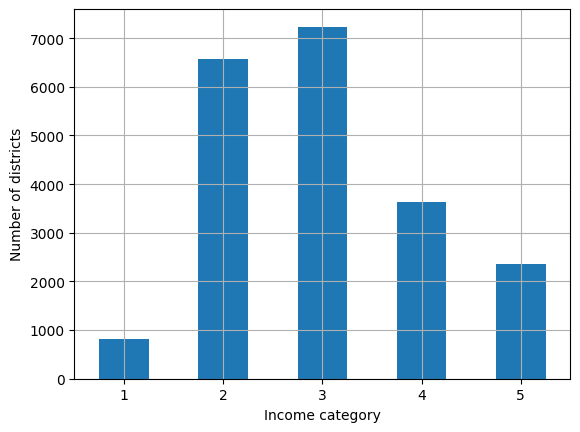

In [10]:
df['income_cat']=pd.cut(df['median_income'],bins=[0.,1.5,3.0,4.5,6.,np.inf],labels=[1,2,3,4,5])
df['income_cat'].value_counts().sort_index().plot.bar(rot=0,grid=True)
plt.xlabel('Income category')
plt.ylabel('Number of districts')
plt.show()

In [11]:
from sklearn.model_selection import train_test_split
train_set,test_set=train_test_split(df,test_size=0.2,stratify=df['income_cat'],random_state=42)

In [12]:
for set_ in (train_set,test_set):
    set_.drop('income_cat',axis=1,inplace=True)

In [13]:
df=train_set.copy()

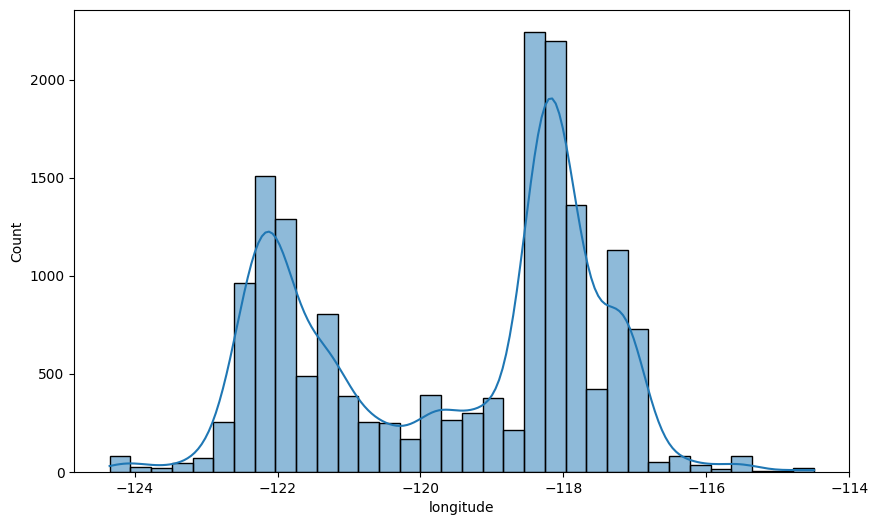

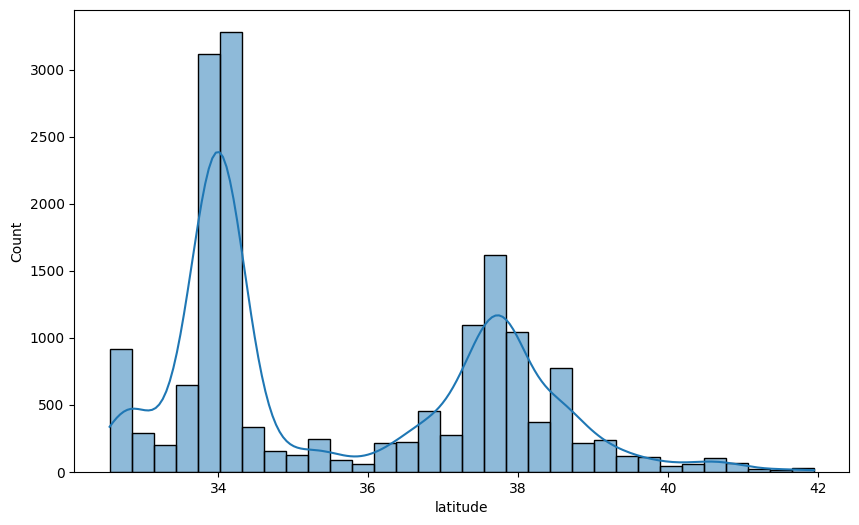

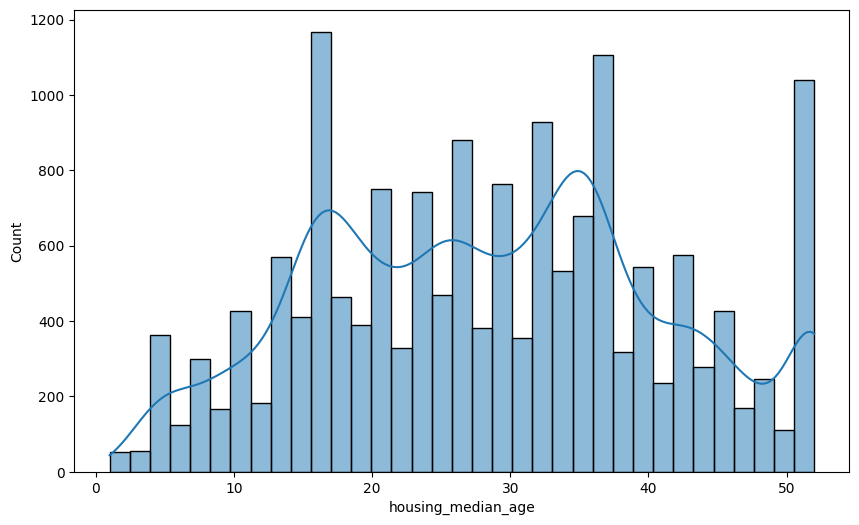

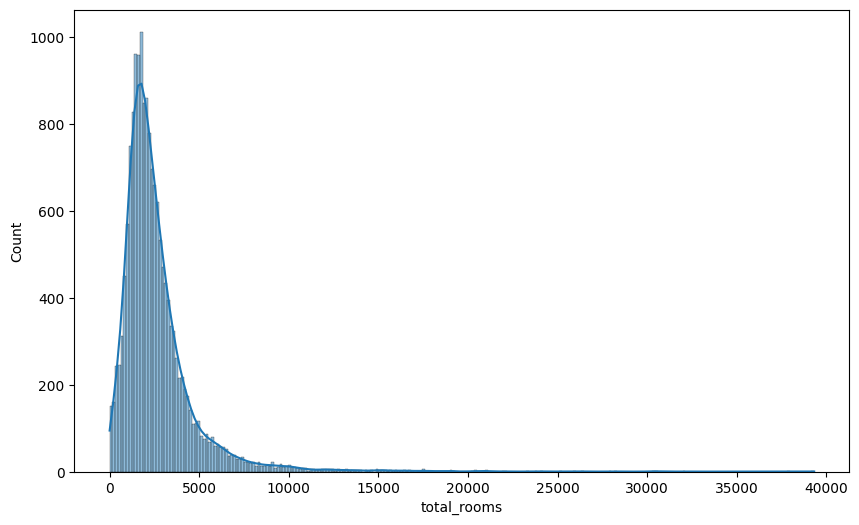

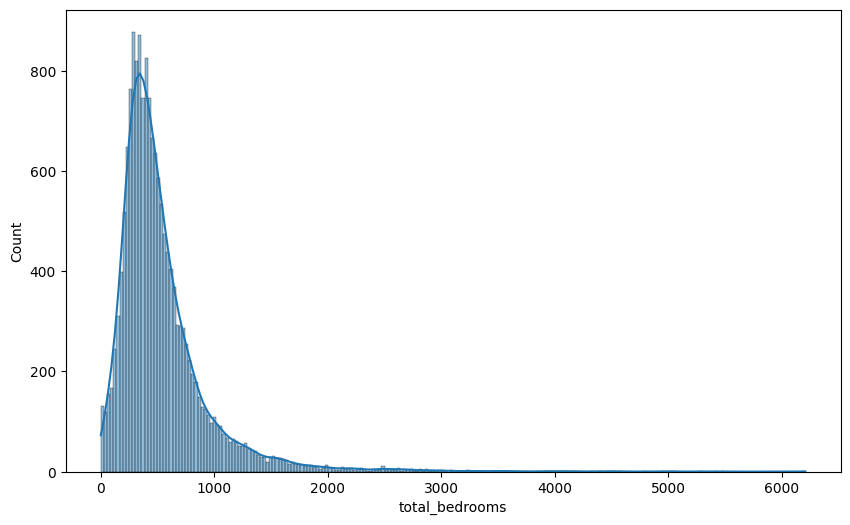

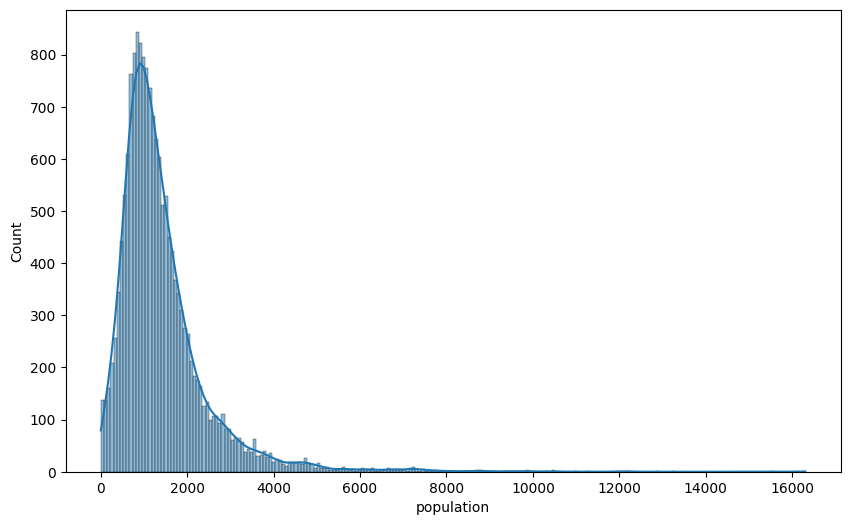

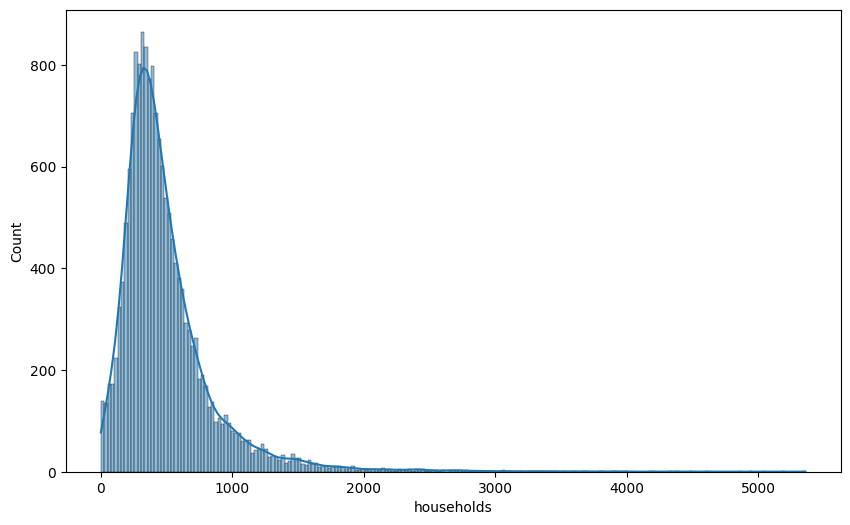

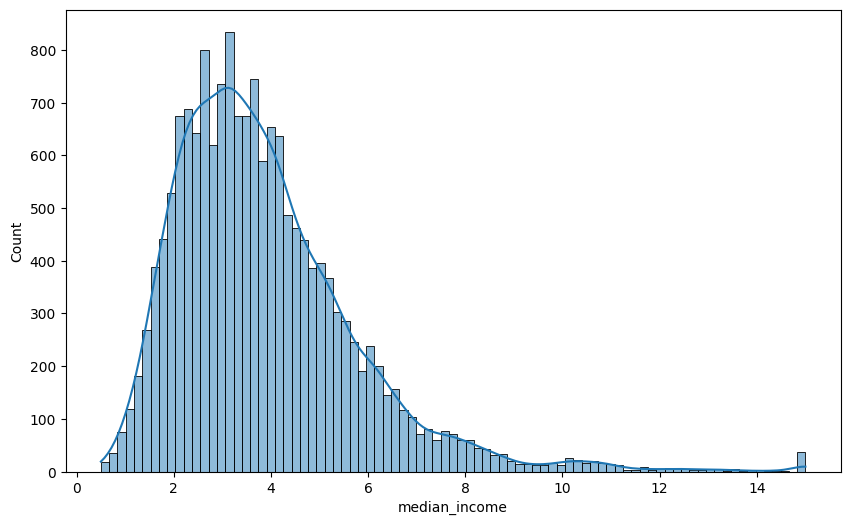

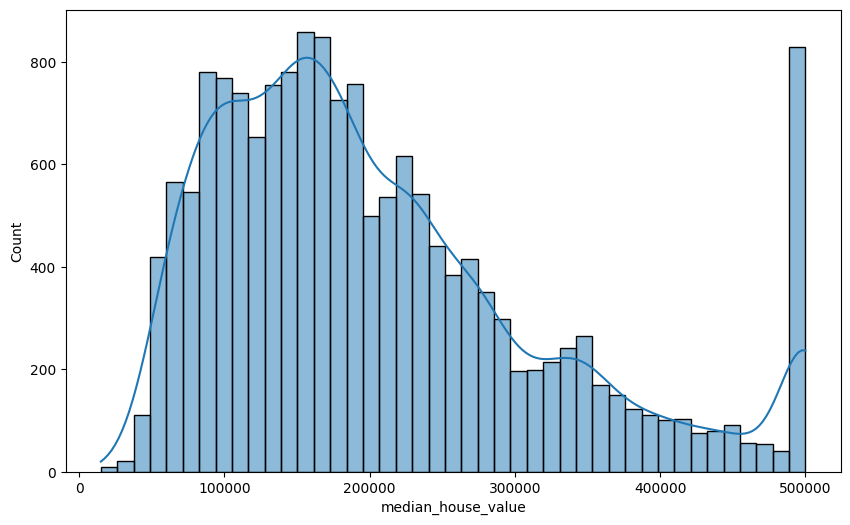

In [14]:
for col in df.select_dtypes(include=np.number).columns:
  plt.figure(figsize=(10,6))
  sns.histplot(df[col],kde=True)
  plt.show()

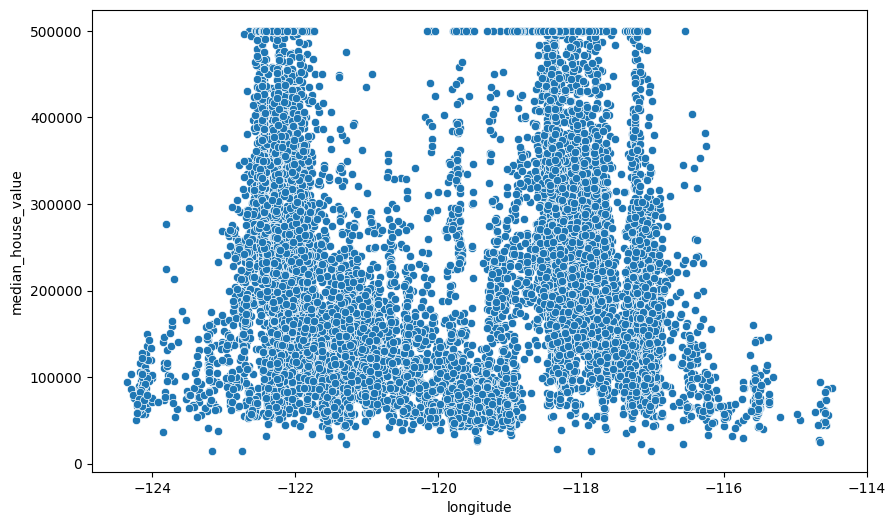

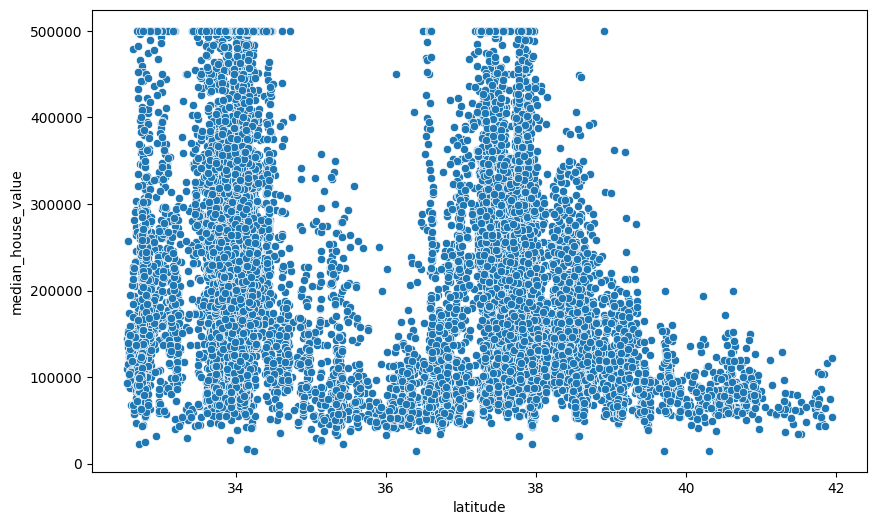

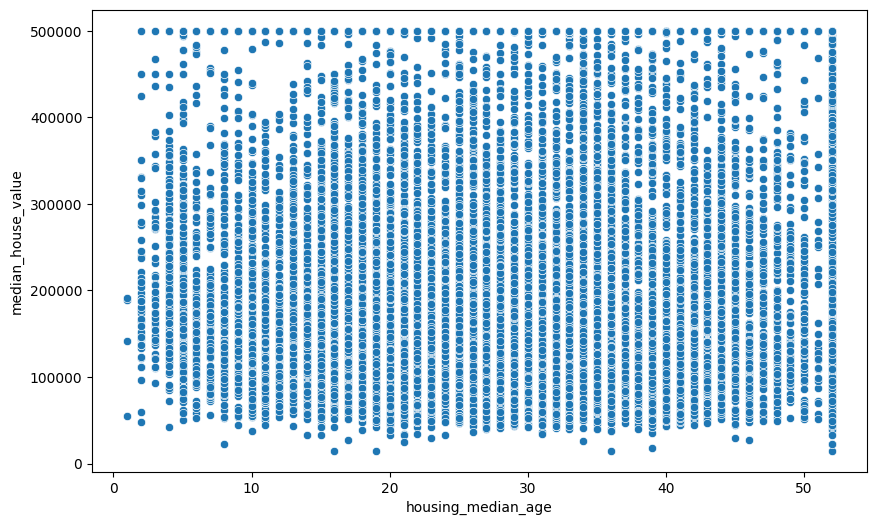

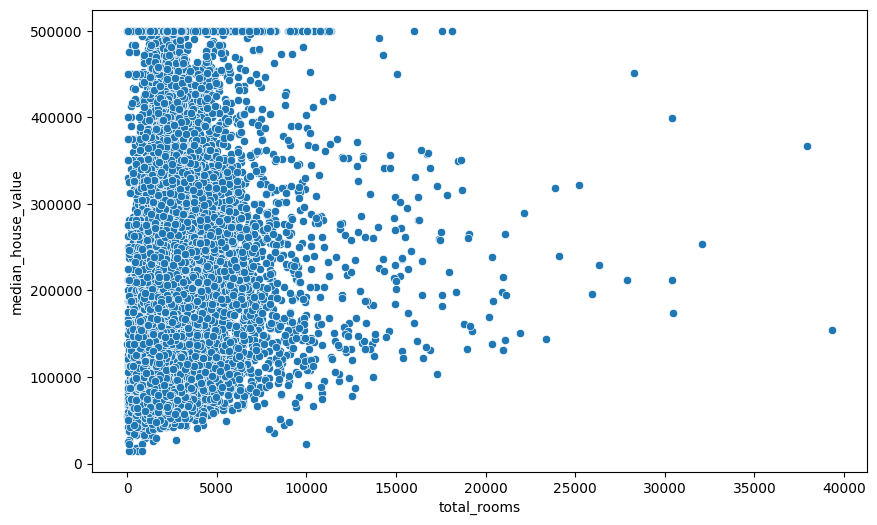

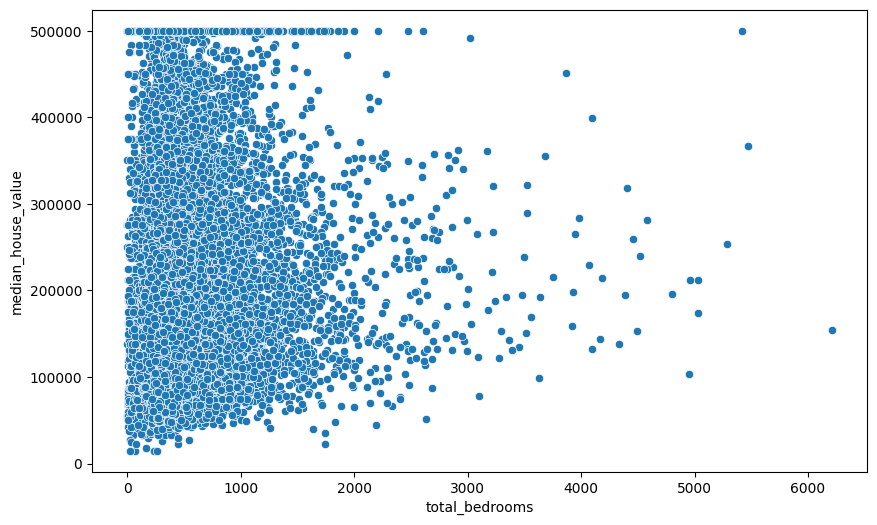

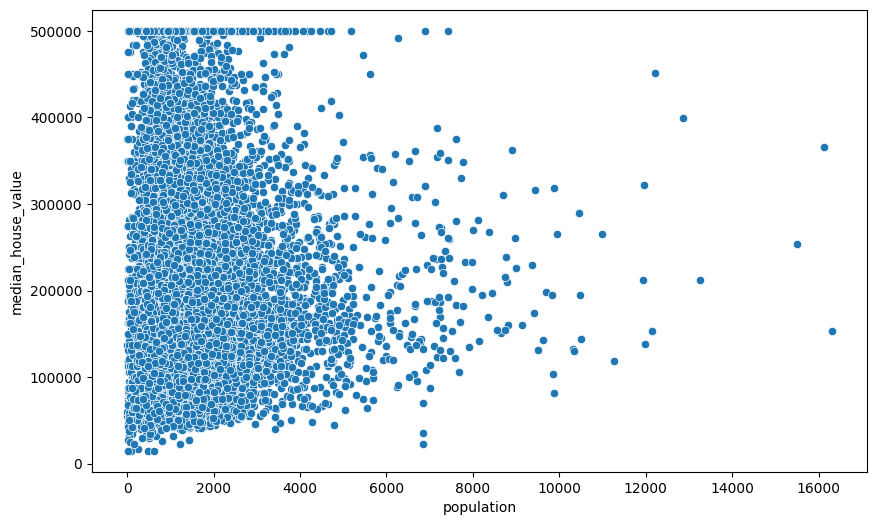

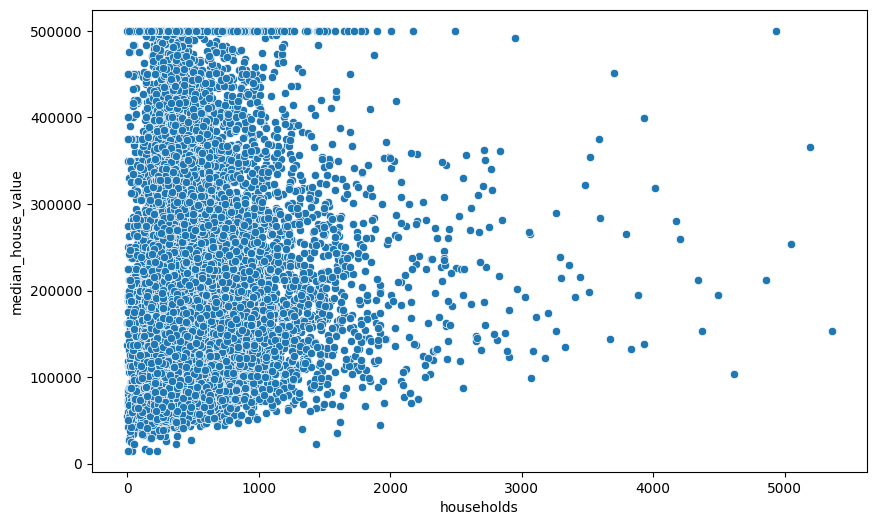

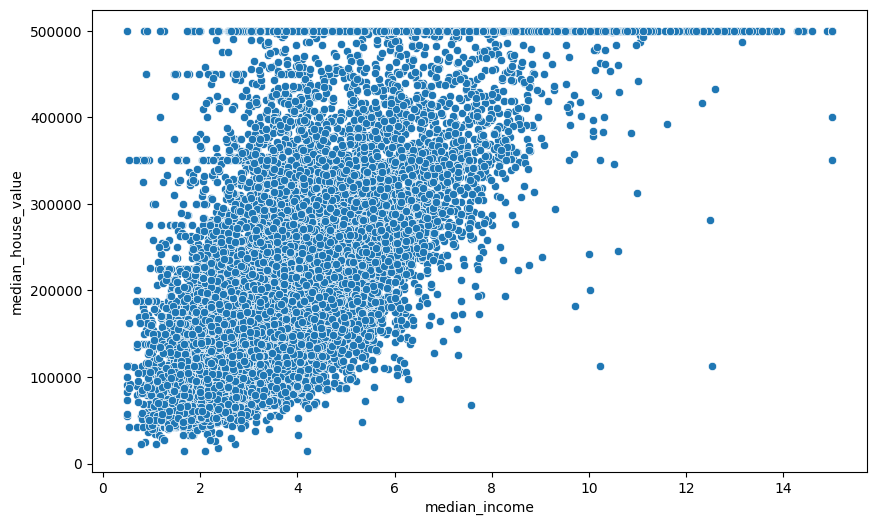

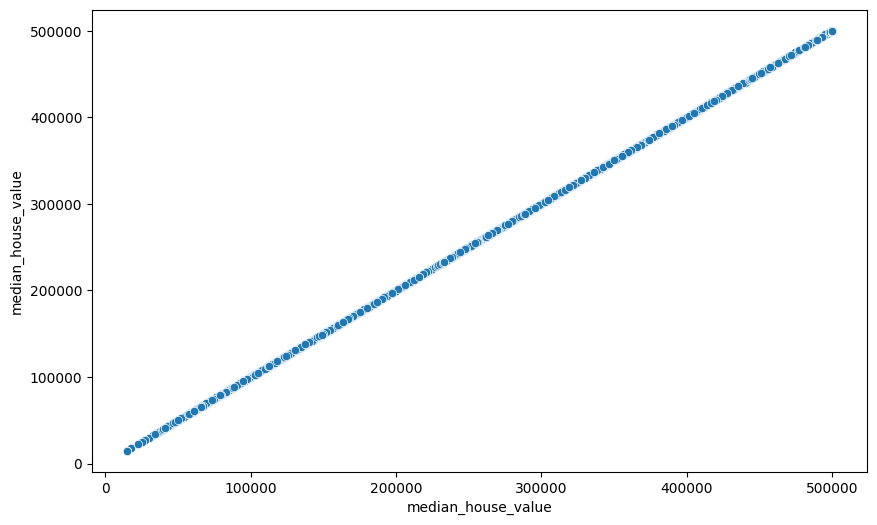

In [15]:
for col in df.select_dtypes(include=np.number).columns:
  plt.figure(figsize=(10,6))
  sns.scatterplot(x=df[col],y=df['median_house_value'])
  plt.show()

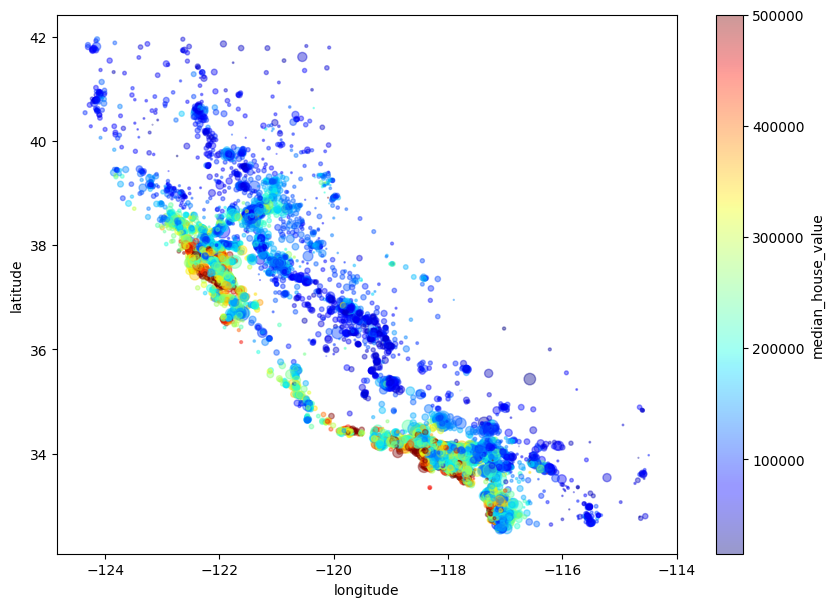

In [16]:
plt.figure(figsize=(10,7))
plt.scatter(df['longitude'],df['latitude'],s=df['population']/100,c=df['median_house_value'],cmap='jet',alpha=0.4)
plt.colorbar(label='median_house_value')
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.show()

In [17]:
corr_matrix=df.corr(numeric_only=True)
corr_matrix['median_house_value'].sort_values(ascending=False)

,median_house_value
median_house_value,1.000000
median_income,0.688380
total_rooms,0.137455
housing_median_age,0.102175
households,0.071426
total_bedrooms,0.054635
population,-0.020153
longitude,-0.050859
latitude,-0.139584


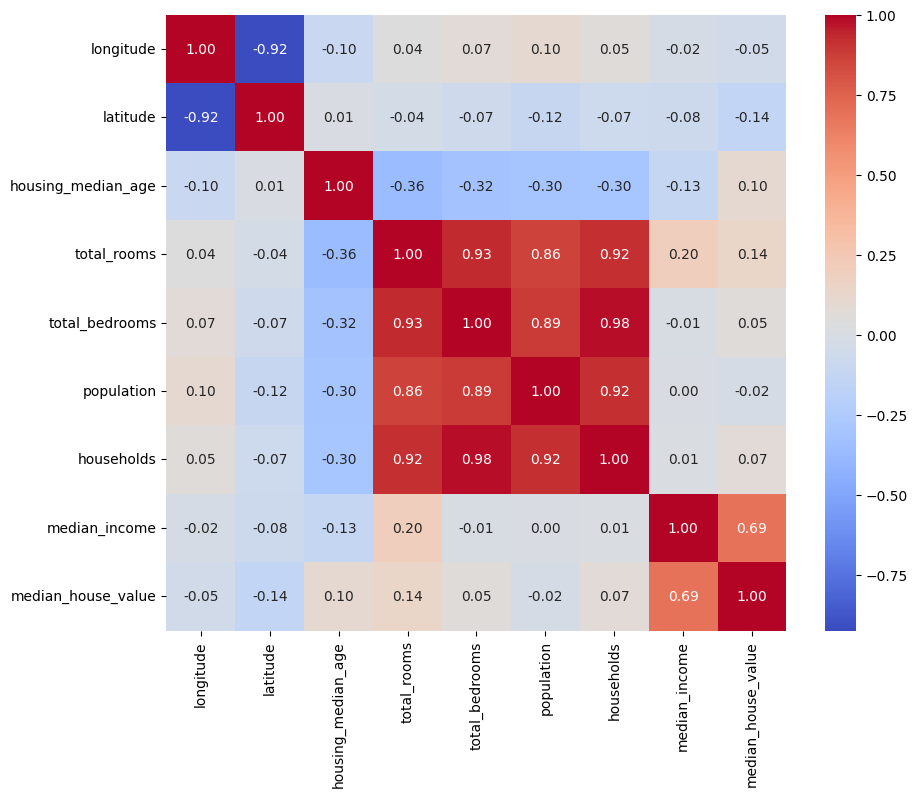

In [18]:
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix,annot=True,fmt='.2f',cmap='coolwarm')
plt.show()

In [19]:
df['rooms_per_house']=df['total_rooms']/df['households']
df['bedrooms_ratio']=df['total_bedrooms']/df['total_rooms']
df['people_per_house']=df['population']/df['households']

In [20]:
df.corr(numeric_only=True)['median_house_value'].sort_values(ascending=False)

,median_house_value
median_house_value,1.000000
median_income,0.688380
rooms_per_house,0.143663
total_rooms,0.137455
housing_median_age,0.102175
households,0.071426
total_bedrooms,0.054635
population,-0.020153
people_per_house,-0.038224
longitude,-0.050859


In [21]:
X_train=train_set.drop('median_house_value',axis=1)
y_train=train_set['median_house_value']
X_test=test_set.drop('median_house_value',axis=1)
y_test=test_set['median_house_value']

In [22]:
for X_ in (X_train,X_test):
    X_['rooms_per_house']=X_['total_rooms']/X_['households']
    X_['bedrooms_ratio']=X_['total_bedrooms']/X_['total_rooms']
    X_['people_per_house']=X_['population']/X_['households']

In [23]:
X_train=pd.get_dummies(X_train,columns=['ocean_proximity'],dtype=int)
X_test=pd.get_dummies(X_test,columns=['ocean_proximity'],dtype=int)
X_test=X_test.reindex(columns=X_train.columns,fill_value=0)
X_train.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_house,bedrooms_ratio,people_per_house,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987,3.211799,0.335742,1.524178,0,0,0,1,0
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876,5.504202,0.180153,1.865546,1,0,0,0,0
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330,5.334975,0.200369,2.768473,0,1,0,0,0
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618,5.351282,0.203881,2.365385,0,1,0,0,0
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292,3.725256,0.277371,1.631399,0,0,0,0,1


In [24]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(strategy='median')
X_train_imp=imputer.fit_transform(X_train)
X_test_imp=imputer.transform(X_test)

In [25]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaler=scaler.fit_transform(X_train_imp)
X_test_scaler=scaler.transform(X_test_imp)

In [26]:
from sklearn.linear_model import LinearRegression
lin_reg=LinearRegression()
lin_reg.fit(X_train_scaler,y_train)

LinearRegression()

In [27]:
from sklearn.metrics import root_mean_squared_error
lin_pred=lin_reg.predict(X_train_scaler)
lin_rmse=root_mean_squared_error(y_train,lin_pred)
lin_rmse

67269.98114035041

In [28]:
from sklearn.tree import DecisionTreeRegressor
tree_reg=DecisionTreeRegressor(random_state=42)
tree_reg.fit(X_train_scaler,y_train)
tree_pred=tree_reg.predict(X_train_scaler)
tree_rmse=root_mean_squared_error(y_train,tree_pred)
tree_rmse

0.0

In [29]:
from sklearn.model_selection import cross_val_score
tree_rmses=-cross_val_score(tree_reg,X_train_scaler,y_train,scoring='neg_root_mean_squared_error',cv=10)
pd.Series(tree_rmses).describe()

,0
count,10.000000
mean,69770.341083
std,2043.779213
min,66440.324894
25%,68962.974216
50%,69418.517534
75%,70999.343642
max,73433.474839


In [30]:
lin_rmses=-cross_val_score(lin_reg,X_train_scaler,y_train,scoring='neg_root_mean_squared_error',cv=10)
pd.Series(lin_rmses).describe()

,0
count,10.000000
mean,67398.944932
std,1297.313438
min,65695.029398
25%,66384.388907
50%,67101.959029
75%,68456.524421
max,69388.330719


In [31]:
from sklearn.ensemble import RandomForestRegressor
forest_reg=RandomForestRegressor(random_state=42)
forest_rmses=-cross_val_score(forest_reg,X_train_scaler,y_train,scoring='neg_root_mean_squared_error',cv=10)
pd.Series(forest_rmses).describe()

,0
count,10.000000
mean,49589.101995
std,1021.045540
min,47650.260345
25%,48979.038947
50%,49854.970675
75%,50085.066249
max,51351.607011


In [32]:
from sklearn.model_selection import GridSearchCV
param_grid={'n_estimators':[50,100],'max_features':[4,6,8]}
grid_search=GridSearchCV(forest_reg,param_grid,cv=3,scoring='neg_root_mean_squared_error')
grid_search.fit(X_train_scaler,y_train)

GridSearchCV(cv=3, estimator=RandomForestRegressor(random_state=42),
             param_grid={'max_features': [4, 6, 8], 'n_estimators': [50, 100]},
             scoring='neg_root_mean_squared_error')

In [33]:
grid_search.best_params_

{'max_features': 6, 'n_estimators': 100}

In [34]:
grid_search.best_estimator_

RandomForestRegressor(max_features=6, random_state=42)

In [35]:
cv_res=pd.DataFrame(grid_search.cv_results_)
cv_res['mean_rmse']=-cv_res['mean_test_score']
cv_res.sort_values(by='mean_rmse')[['param_n_estimators','param_max_features','mean_rmse']]

,param_n_estimators,param_max_features,mean_rmse
3,100,6,49466.913787
2,50,6,49753.269948
5,100,8,49763.398076
1,100,4,49944.212805
4,50,8,50177.228170
0,50,4,50201.828758


In [36]:
final_model=grid_search.best_estimator_
feature_importances=pd.DataFrame({'Feature':X_train.columns,'Importance':final_model.feature_importances_})
feature_importances=feature_importances.sort_values(by='Importance',ascending=False)
feature_importances

,Feature,Importance
7,median_income,0.325695
12,ocean_proximity_INLAND,0.152718
10,people_per_house,0.110475
9,bedrooms_ratio,0.080553
0,longitude,0.075831
1,latitude,0.067874
8,rooms_per_house,0.057686
2,housing_median_age,0.042381
3,total_rooms,0.017480
5,population,0.017169


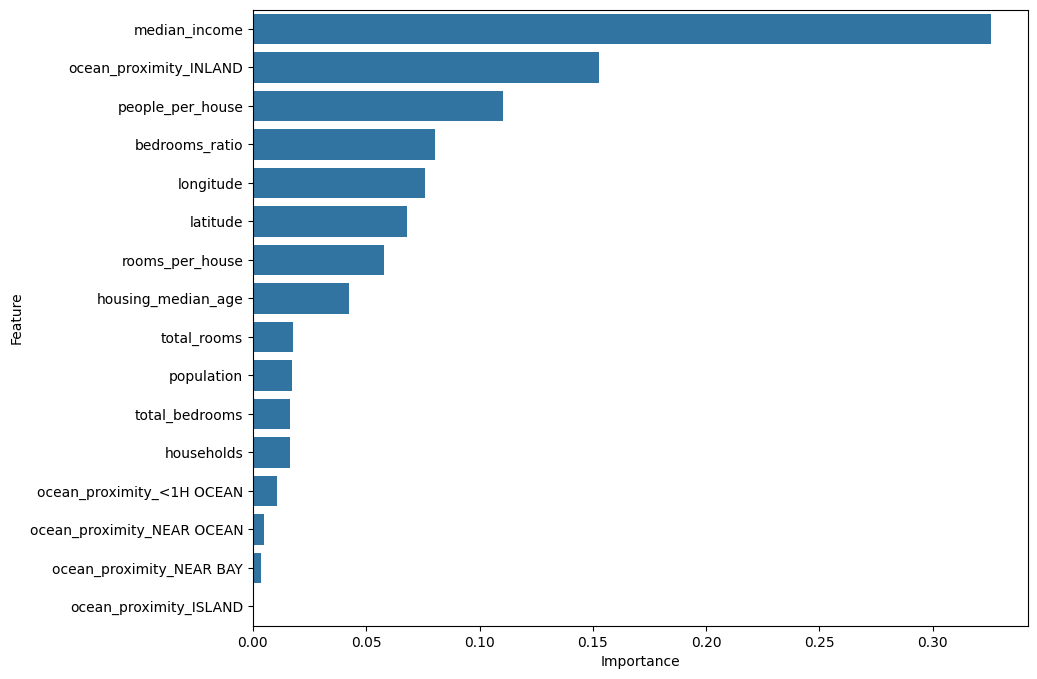

In [37]:
plt.figure(figsize=(10,8))
sns.barplot(data=feature_importances,x='Importance',y='Feature')
plt.show()

In [38]:
y_pred=final_model.predict(X_test_scaler)

In [39]:
from sklearn.metrics import mean_absolute_error
mae=mean_absolute_error(y_test,y_pred)
mae

32092.354743217053

In [40]:
rmse=root_mean_squared_error(y_test,y_pred)
rmse

48865.28765045838

In [41]:
from sklearn.metrics import r2_score
r2score=r2_score(y_test,y_pred)
r2score

0.8216178772755944

In [42]:
import joblib
joblib.dump(final_model,'california_housing_model.pkl')
joblib.dump(imputer,'imputer.pkl')
joblib.dump(scaler,'scaler.pkl')

['scaler.pkl']